# WAFER-GUARD — Repaired Wafer Anomaly Detector

This notebook implements a causality-conscious audit and evaluation pipeline for `secom_telemetry_modified.csv`.

**Important:** results are measured by executing this notebook. Do not substitute expected or previously reported scores for the outputs produced here. The evaluator-only mask file is not used for feature construction, fitting, threshold selection, or model evaluation.

## 1. Audit plan and constraints

- Sort observations chronologically and use the earliest 60% for training, the next 20% for validation, and the latest 20% for the final test.
- Fit imputation and scaling on training rows only.
- Do not apply SMOTE before splitting; retain natural class prevalence for validation and test.
- Treat `sensor_0 == 0.0` as the legacy-station sentinel, not a genuine continuous measurement.
- For legacy rows, treat `sensor_1` values 100, 200, and 300 as categories. Encode them as indicator features. The sentinel/code slots are neutralized after scaling and masked out of reconstruction loss, so fabricated median values are neither input signals nor reconstruction targets.
- Keep each input/reconstruction tensor at shape `[batch, features]`, preventing unintended batch-axis broadcasting in reconstruction loss.
- Choose a classification threshold on validation data only, then evaluate the frozen threshold once on the later test period.

In [24]:
import os, random, json, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 1337
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HP = dict(batch_size=64, epochs=30, lr=1e-3, weight_decay=1e-5,
          hidden=256, latent=32, lambda_clf=1.0)
DATA_PATH = "secom_telemetry_modified.csv"
print(f"torch={torch.__version__} | device={DEVICE}")

torch=2.14.1+cpu | device=cpu


In [25]:
# Demonstrate the original silent broadcasting bug explicitly (shape-only evidence).
# These tensors are small enough for a quick regression demonstration.
original_x_shape = torch.empty(64, 1, 590)
original_reconstruction_shape = torch.empty(64, 590)
broadcast_shape = (original_x_shape - original_reconstruction_shape).shape
print("Original subtraction broadcast shape:", broadcast_shape)
assert tuple(broadcast_shape) == (64, 64, 590)
print("PASS: demonstrates why [B, 1, F] vs [B, F] is incorrect.")

Original subtraction broadcast shape: torch.Size([64, 64, 590])
PASS: demonstrates why [B, 1, F] vs [B, F] is incorrect.


In [26]:
df = pd.read_csv(DATA_PATH)
required = {"label", "timestamp"}
assert required.issubset(df.columns), f"Missing required columns: {required - set(df.columns)}"
SENSOR_COLS = [c for c in df.columns if c.startswith("sensor_")]
assert len(SENSOR_COLS) == 590, f"Expected 590 sensor columns, got {len(SENSOR_COLS)}"
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="raise")
df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)
y = (df["label"].to_numpy() == 1).astype(np.int64)
print("rows:", len(df), "sensors:", len(SENSOR_COLS), "natural defect prevalence:", f"{y.mean():.4%}")
print("timestamp range:", df.timestamp.min(), "to", df.timestamp.max())
print("label counts:", pd.Series(y).value_counts().sort_index().to_dict())

rows: 1567 sensors: 590 natural defect prevalence: 6.6369%
timestamp range: 2008-07-19 11:55:00 to 2008-10-17 06:07:00
label counts: {0: 1463, 1: 104}


## 2. Chronological split and legacy-tool feature construction

The split happens before any learned preprocessing. The legacy indicator is derived only from the row's own sentinel (`sensor_0 == 0.0`). `sensor_1` legacy codes become categorical flags; they are not treated as continuous magnitudes. For legacy rows, the two continuous slots are set to neutral zero after scaling and excluded from reconstruction loss. The separate `secom_legacy_mask_EVALUATOR_ONLY.csv` is intentionally not read by this pipeline.

In [27]:
n = len(df)
train_end = int(n * 0.60)
val_end = int(n * 0.80)
train_idx = np.arange(0, train_end)
val_idx = np.arange(train_end, val_end)
test_idx = np.arange(val_end, n)
assert train_idx[-1] < val_idx[0] < test_idx[0]

raw = df[SENSOR_COLS].copy()
legacy = raw["sensor_0"].eq(0.0)
legacy_codes = raw["sensor_1"].isin([100.0, 200.0, 300.0])
print("legacy rows inferred from sensor_0 sentinel:", int(legacy.sum()))
print("legacy-coded sensor_1 rows:", int(legacy_codes.sum()))
print("legacy sensor_1 values:", raw.loc[legacy, "sensor_1"].value_counts(dropna=False).to_dict())

# Keep explicit categorical indicators; never scale or impute the code values as continuous data.
X_df = raw.copy()
X_df["legacy_station"] = legacy.astype(float)
for code_value in (100.0, 200.0, 300.0):
    X_df[f"sensor_1_legacy_code_{int(code_value)}"] = (legacy & raw["sensor_1"].eq(code_value)).astype(float)
# sensor_0's zero is a sentinel, so replace it with missing before fitting imputation.
X_df.loc[legacy, "sensor_0"] = np.nan
# sensor_1 is categorical on legacy rows; remove those codes from its continuous feature.
X_df.loc[legacy, "sensor_1"] = np.nan
FEATURE_COLS = list(X_df.columns)
continuous_cols = SENSOR_COLS.copy()
# Binary indicator columns are appended after continuous preprocessing and are not scaled.
indicator_cols = ["legacy_station", "sensor_1_legacy_code_100", "sensor_1_legacy_code_200", "sensor_1_legacy_code_300"]
print("feature count after explicit legacy indicators:", len(FEATURE_COLS))

legacy rows inferred from sensor_0 sentinel: 146
legacy-coded sensor_1 rows: 146
legacy sensor_1 values: {100.0: 61, 300.0: 50, 200.0: 35}
feature count after explicit legacy indicators: 594


In [28]:
# Fit imputer and scaler using training rows ONLY.
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
scaler = StandardScaler()
X_train_cont = imputer.fit_transform(X_df.iloc[train_idx][continuous_cols])
X_train_cont = scaler.fit_transform(X_train_cont)
X_val_cont = scaler.transform(imputer.transform(X_df.iloc[val_idx][continuous_cols]))
X_test_cont = scaler.transform(imputer.transform(X_df.iloc[test_idx][continuous_cols]))

# Strict PS-L handling: do not leave fitted median values in the sentinel/code slots.
# The four indicators carry legacy status/code information instead.
legacy_np = legacy.to_numpy(dtype=bool)
for X_part, idx in ((X_train_cont, train_idx), (X_val_cont, val_idx), (X_test_cont, test_idx)):
    local_legacy = legacy_np[idx]
    X_part[local_legacy, 0] = 0.0
    X_part[local_legacy, 1] = 0.0

X_train_ind = X_df.iloc[train_idx][indicator_cols].to_numpy(dtype=np.float32)
X_val_ind = X_df.iloc[val_idx][indicator_cols].to_numpy(dtype=np.float32)
X_test_ind = X_df.iloc[test_idx][indicator_cols].to_numpy(dtype=np.float32)
X_train = np.concatenate([X_train_cont.astype(np.float32), X_train_ind], axis=1)
X_val = np.concatenate([X_val_cont.astype(np.float32), X_val_ind], axis=1)
X_test = np.concatenate([X_test_cont.astype(np.float32), X_test_ind], axis=1)

# Per-cell reconstruction mask: legacy sensor_0/sensor_1 slots are not targets.
M_train = np.ones_like(X_train, dtype=np.float32)
M_val = np.ones_like(X_val, dtype=np.float32)
M_test = np.ones_like(X_test, dtype=np.float32)
for mask, idx in ((M_train, train_idx), (M_val, val_idx), (M_test, test_idx)):
    local_legacy = legacy_np[idx]
    mask[local_legacy, 0] = 0.0
    mask[local_legacy, 1] = 0.0

y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
print("shapes:", X_train.shape, X_val.shape, X_test.shape)
print("prevalence train/validation/test:", *(f"{a.mean():.4%}" for a in (y_train, y_val, y_test)))
print("masked legacy reconstruction targets (train/val/test):", int((M_train[:, :2] == 0).sum()), int((M_val[:, :2] == 0).sum()), int((M_test[:, :2] == 0).sum()))
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
assert np.all(X_train[legacy_np[train_idx], :2] == 0.0)
assert np.all(X_val[legacy_np[val_idx], :2] == 0.0)
assert np.all(X_test[legacy_np[test_idx], :2] == 0.0)

shapes: (940, 594) (313, 594) (314, 594)
prevalence train/validation/test: 8.0851% 3.5144% 5.4140%
masked legacy reconstruction targets (train/val/test): 158 80 54


## 3. Model and training

No synthetic samples are created. To account for the naturally imbalanced training labels, the classification loss uses a positive-class weight estimated from the training period only. Reconstruction loss and classification loss operate on aligned `[batch, features]` and `[batch]` tensors. A per-feature mask excludes the two legacy sentinel/code slots from reconstruction loss.

In [29]:
def make_loader(X, y, mask, shuffle=False):
    Xt = torch.from_numpy(np.asarray(X, dtype=np.float32))  # [N, F], no extra channel axis
    yt = torch.from_numpy(np.asarray(y, dtype=np.float32))  # [N]
    mt = torch.from_numpy(np.asarray(mask, dtype=np.float32))  # [N, F]
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(TensorDataset(Xt, yt, mt), batch_size=HP["batch_size"],
                      shuffle=shuffle, generator=generator, drop_last=False)

train_loader = make_loader(X_train, y_train, M_train, shuffle=True)
val_loader = make_loader(X_val, y_val, M_val, shuffle=False)
test_loader = make_loader(X_test, y_test, M_test, shuffle=False)
F = X_train.shape[1]

class WaferSAE(nn.Module):
    def __init__(self, d_in, d_hid, d_lat):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(d_in, d_hid), nn.LayerNorm(d_hid), nn.GELU(),
                                     nn.Dropout(0.10), nn.Linear(d_hid, d_hid // 2),
                                     nn.LayerNorm(d_hid // 2), nn.GELU(), nn.Linear(d_hid // 2, d_lat))
        self.decoder = nn.Sequential(nn.Linear(d_lat, d_hid // 2), nn.GELU(),
                                     nn.Linear(d_hid // 2, d_hid), nn.GELU(), nn.Linear(d_hid, d_in))
        self.head = nn.Linear(d_lat, 1)
    def forward(self, x):
        # x and reconstruction are both [B, F]; logits are [B].
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        logits = self.head(z).squeeze(-1)
        return reconstruction, logits, z

model = WaferSAE(F, HP["hidden"], HP["latent"]).to(DEVICE)
pos = float(y_train.sum()); neg = float(len(y_train) - y_train.sum())
pos_weight = torch.tensor([neg / max(pos, 1.0)], dtype=torch.float32, device=DEVICE)
bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=HP["epochs"])
print("input features:", F, "positive-class weight:", float(pos_weight.item()))

input features: 594 positive-class weight: 11.368420600891113


In [30]:
history = {"total": [], "reconstruction": [], "classification": []}
for epoch in range(1, HP["epochs"] + 1):
    model.train()
    totals = np.zeros(3, dtype=float); batches = 0
    for xb, yb, mb in train_loader:
        xb, yb, mb = xb.to(DEVICE), yb.to(DEVICE), mb.to(DEVICE)
        reconstruction, logits, _ = model(xb)
        assert reconstruction.shape == xb.shape, (reconstruction.shape, xb.shape)
        assert logits.shape == yb.shape, (logits.shape, yb.shape)
        squared_error = (reconstruction - xb) ** 2
        recon_loss = (squared_error * mb).sum() / mb.sum().clamp(min=1.0)
        clf_loss = bce(logits, yb)
        loss = recon_loss + HP["lambda_clf"] * clf_loss
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        totals += [loss.item(), recon_loss.item(), clf_loss.item()]
        batches += 1
    sched.step()
    totals /= max(batches, 1)
    for k, value in zip(history, totals): history[k].append(float(value))
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:02d}/{HP['epochs']} | total={totals[0]:.4f} recon={totals[1]:.4f} clf={totals[2]:.4f}")

epoch 01/30 | total=2.0534 recon=0.7865 clf=1.2669
epoch 05/30 | total=0.7459 recon=0.7150 clf=0.0309
epoch 10/30 | total=0.6049 recon=0.6023 clf=0.0025
epoch 15/30 | total=0.5616 recon=0.5602 clf=0.0014
epoch 20/30 | total=0.5367 recon=0.5356 clf=0.0011
epoch 25/30 | total=0.5214 recon=0.5205 clf=0.0009
epoch 30/30 | total=0.5189 recon=0.5180 clf=0.0009


## 4. Metrics and validation-only threshold

At the natural test prevalence of about 5.4%, average precision (AP) is the primary ranking metric because it can be compared with the defect prevalence; ROC-AUC alone does not show the false-alarm burden. F1, precision, and recall describe one operating point. We select the F1-maximizing threshold on the later validation split only, freeze it, and score the final chronological test once. This threshold procedure is intentionally reported even though it may be unstable with few validation defects. The final report includes the number of wafers flagged and false alarms, plus fixed top-k alert-budget metrics. No test metric is used to tune the model or threshold.

In [31]:
def predict_probabilities(loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for xb, yb, _ in loader:
            _, logits, _ = model(xb.to(DEVICE))
            ps.extend(torch.sigmoid(logits).cpu().numpy().tolist())
            ys.extend(yb.numpy().astype(int).tolist())
    return np.asarray(ys, dtype=int), np.asarray(ps, dtype=float)

yv, pv = predict_probabilities(val_loader)
thresholds = np.unique(np.concatenate(([0.0, 0.5, 1.0], pv)))
val_scores = [(float(t), f1_score(yv, (pv >= t).astype(int), zero_division=0)) for t in thresholds]
threshold, val_f1 = max(val_scores, key=lambda z: (z[1], -abs(z[0] - 0.5)))
print(f"validation-selected threshold={threshold:.6f} | validation F1={val_f1:.4f}")

validation-selected threshold=0.000041 | validation F1=0.0769


In [32]:
yt, pt = predict_probabilities(test_loader)
pred = (pt >= threshold).astype(int)
metrics = {
    "threshold_selected_on_validation": float(threshold),
    "test_rows": int(len(yt)),
    "test_defect_prevalence": float(yt.mean()),
    "f1": float(f1_score(yt, pred, zero_division=0)),
    "precision": float(precision_score(yt, pred, zero_division=0)),
    "recall": float(recall_score(yt, pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(yt, pt)) if len(np.unique(yt)) == 2 else None,
    "average_precision": float(average_precision_score(yt, pt)),
    "confusion_matrix_tn_fp_fn_tp": confusion_matrix(yt, pred, labels=[0,1]).ravel().tolist(),
}
print(json.dumps(metrics, indent=2))
print("\nTest classification report (natural prevalence):")
print(classification_report(yt, pred, target_names=["pass", "defect"], zero_division=0))

# Descriptive ranking metrics: alert-budget view and iid bootstrap uncertainty.
# These are reporting-only: no test result is used to change the model or threshold.
order = np.argsort(-pt, kind="stable")
topk_report = {}
for fraction in (0.05, 0.10):
    k = max(1, int(np.ceil(fraction * len(yt))))
    chosen = order[:k]
    tp_k = int(yt[chosen].sum())
    topk_report[f"top_{int(fraction*100)}pct"] = {
        "k": int(k),
        "precision_at_k": float(tp_k / k),
        "recall_at_k": float(tp_k / max(1, int(yt.sum()))),
        "true_positives": tp_k,
    }

rng = np.random.default_rng(20261018)
bootstrap_n = 2000
boot = {"f1": [], "precision": [], "recall": [], "roc_auc": [], "average_precision": []}
for _ in range(bootstrap_n):
    ids = rng.integers(0, len(yt), size=len(yt))
    yb, pb, pred_b = yt[ids], pt[ids], pred[ids]
    boot["f1"].append(float(f1_score(yb, pred_b, zero_division=0)))
    boot["precision"].append(float(precision_score(yb, pred_b, zero_division=0)))
    boot["recall"].append(float(recall_score(yb, pred_b, zero_division=0)))
    if len(np.unique(yb)) == 2:
        boot["roc_auc"].append(float(roc_auc_score(yb, pb)))
        boot["average_precision"].append(float(average_precision_score(yb, pb)))
bootstrap_ci = {}
for metric_name, values in boot.items():
    if values:
        bootstrap_ci[metric_name] = [
            float(np.quantile(values, 0.025)),
            float(np.quantile(values, 0.975)),
        ]
metrics["top_k_alert_metrics"] = topk_report
metrics["iid_bootstrap_95pct_ci"] = bootstrap_ci
metrics["iid_bootstrap_replicates"] = bootstrap_n
metrics["iid_bootstrap_note"] = (
    "Row-wise percentile bootstrap for descriptive uncertainty only; "
    "does not account for temporal dependence and is not used for model selection."
)
with open("artifacts/test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
np.savez("artifacts/test_predictions.npz", y_true=yt, probabilities=pt, predictions=pred)
print("Top-k alert metrics:", json.dumps(topk_report, indent=2))
print("IID bootstrap 95% intervals:", json.dumps(bootstrap_ci, indent=2))


{
  "threshold_selected_on_validation": 4.072272349731065e-05,
  "test_rows": 314,
  "test_defect_prevalence": 0.054140127388535034,
  "f1": 0.13114754098360656,
  "precision": 0.07228915662650602,
  "recall": 0.7058823529411765,
  "roc_auc": 0.6242820360467418,
  "average_precision": 0.08411434649894632,
  "confusion_matrix_tn_fp_fn_tp": [
    143,
    154,
    5,
    12
  ]
}

Test classification report (natural prevalence):
              precision    recall  f1-score   support

        pass       0.97      0.48      0.64       297
      defect       0.07      0.71      0.13        17

    accuracy                           0.49       314
   macro avg       0.52      0.59      0.39       314
weighted avg       0.92      0.49      0.62       314

Top-k alert metrics: {
  "top_5pct": {
    "k": 16,
    "precision_at_k": 0.0,
    "recall_at_k": 0.0,
    "true_positives": 0
  },
  "top_10pct": {
    "k": 32,
    "precision_at_k": 0.0625,
    "recall_at_k": 0.11764705882352941,
    "true_

## 5. Shape-regression check and release artifacts

The explicit assertions below are intended to catch the prior reconstruction-loss broadcasting failure. The artifacts store the model weights and the training-fitted preprocessing objects. The strict PS-L variant neutralizes the legacy `sensor_0`/`sensor_1` slots and masks them out of reconstruction loss; the categorical indicators retain legacy information. They do not encode a claim that the model has passed a production release gate; release should depend on the measured test results and residual risks.

In [33]:
# Regression test: model outputs must align exactly with their targets.
probe = torch.from_numpy(X_train[:min(7, len(X_train))]).float().to(DEVICE)
model.eval()
with torch.no_grad():
    recon_probe, logits_probe, _ = model(probe)
assert recon_probe.shape == probe.shape, f"Reconstruction shape mismatch: {recon_probe.shape} vs {probe.shape}"
assert logits_probe.shape == (len(probe),), f"Logit shape mismatch: {logits_probe.shape}"
print("PASS: reconstruction/input and logits/label shapes match exactly.")

os.makedirs("artifacts", exist_ok=True)
torch.save(model.state_dict(), "artifacts/wafer_sae.pt")
import joblib
joblib.dump({"imputer": imputer, "scaler": scaler,
             "continuous_cols": continuous_cols, "indicator_cols": indicator_cols,
             "feature_cols": FEATURE_COLS, "threshold": float(threshold),
             "psl_policy": "strict_neutral_slots_masked_reconstruction"},
            "artifacts/preprocessor.joblib")
with open("artifacts/test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print("Saved artifacts/model weights, preprocessing objects, and measured test metrics.")

PASS: reconstruction/input and logits/label shapes match exactly.
Saved artifacts/model weights, preprocessing objects, and measured test metrics.


## 6. Fixed-model diagnostic checks (no retuning)

These diagnostics evaluate the already-trained model and frozen validation threshold. The label-permutation test is descriptive only: it does not change features, weights, or the operating threshold. Its row-wise permutation null assumes exchangeability and does not account for temporal dependence, so interpret it alongside the pooled out-of-time evaluation.


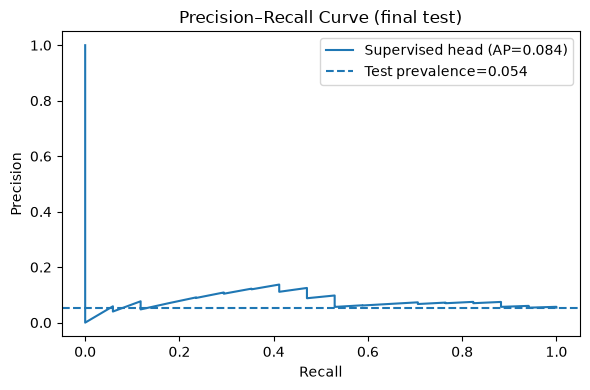

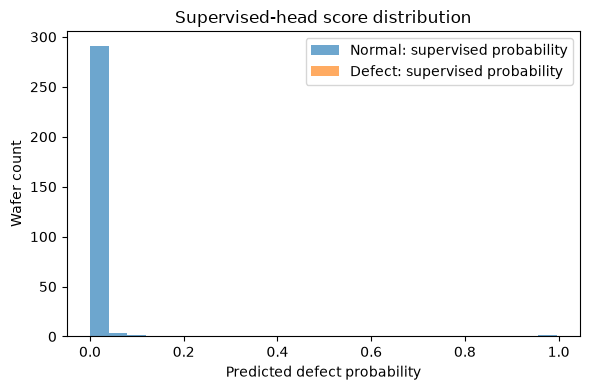

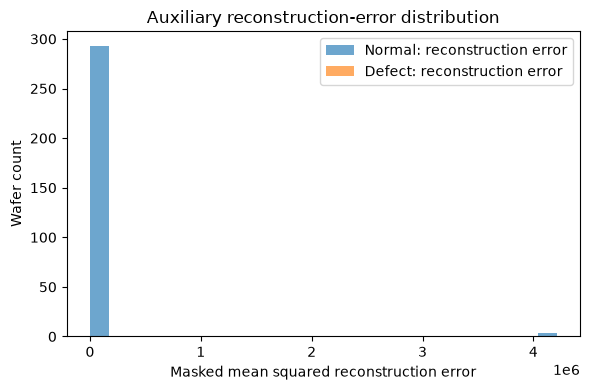

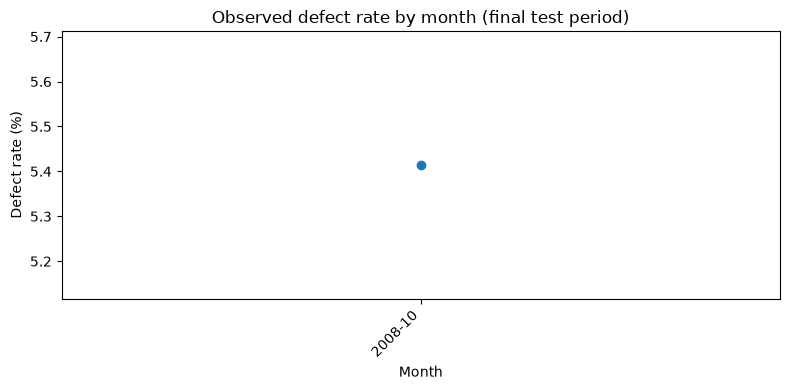

{
  "test_rows": 314,
  "test_prevalence": 0.054140127388535034,
  "permutation_test_method": {
    "permutations": 5000,
    "ap_sidedness": "upper-tail: observed AP or higher",
    "auc_sidedness": "two-sided: absolute distance from 0.5",
    "caveat": "Row-wise label permutation ignores temporal dependence; descriptive only, not used for model selection."
  },
  "supervised_head": {
    "observed_average_precision": 0.08411434649894632,
    "observed_roc_auc": 0.6242820360467418,
    "ap_permutation_p_upper_tail": 0.20295940811837632,
    "auc_permutation_p_two_sided_vs_0_5": 0.08638272345530894,
    "permutations": 5000,
    "null": "row-wise shuffled labels; temporal dependence is ignored"
  },
  "reconstruction_error": {
    "observed_average_precision": 0.04045924128667603,
    "observed_roc_auc": 0.316696375519905,
    "ap_permutation_p_upper_tail": 0.993001399720056,
    "auc_permutation_p_two_sided_vs_0_5": 0.008598280343931213,
    "permutations": 5000,
    "null": "row-wise

In [34]:
# Fixed-model diagnostics only: no model, score direction, or threshold is changed here.
# The supervised probability is the classifier score; reconstruction error is an auxiliary score.
model.eval()
reconstruction_errors = []
with torch.no_grad():
    for xb, yb, mb in test_loader:
        xb, mb = xb.to(DEVICE), mb.to(DEVICE)
        recon, _, _ = model(xb)
        per_row = (((recon - xb) ** 2) * mb).sum(dim=1) / mb.sum(dim=1).clamp(min=1.0)
        reconstruction_errors.extend(per_row.cpu().numpy().tolist())
reconstruction_errors = np.asarray(reconstruction_errors, dtype=float)

PERMUTATION_N = 5000
perm_rng = np.random.default_rng(SEED + 9001)
def permutation_diagnostics(y, score, n_perm, rng):
    observed_auc = float(roc_auc_score(y, score))
    observed_ap = float(average_precision_score(y, score))
    null_auc = np.empty(n_perm, dtype=float)
    null_ap = np.empty(n_perm, dtype=float)
    for j in range(n_perm):
        yp = rng.permutation(y)
        null_auc[j] = roc_auc_score(yp, score)
        null_ap[j] = average_precision_score(yp, score)
    # Explicit sidedness:
    # AP: upper-tail test (is AP larger than values under random label assignment?)
    # AUC: two-sided distance from 0.5 (either direction away from chance).
    p_ap_upper = float((1 + np.sum(null_ap >= observed_ap)) / (n_perm + 1))
    p_auc_two_sided = float((1 + np.sum(np.abs(null_auc - 0.5) >= abs(observed_auc - 0.5))) / (n_perm + 1))
    return {
        "observed_average_precision": observed_ap,
        "observed_roc_auc": observed_auc,
        "ap_permutation_p_upper_tail": p_ap_upper,
        "auc_permutation_p_two_sided_vs_0_5": p_auc_two_sided,
        "permutations": int(n_perm),
        "null": "row-wise shuffled labels; temporal dependence is ignored"
    }

supervised_diag = permutation_diagnostics(yt, pt, PERMUTATION_N, perm_rng)
reconstruction_diag = permutation_diagnostics(yt, reconstruction_errors, PERMUTATION_N, perm_rng)

# Diagnostic plots: PR curve, score distributions, and defect rate by calendar month.
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
pr_precision, pr_recall, _ = precision_recall_curve(yt, pt)
plt.figure(figsize=(6, 4))
plt.plot(pr_recall, pr_precision, label=f"Supervised head (AP={supervised_diag['observed_average_precision']:.3f})")
plt.axhline(float(yt.mean()), linestyle="--", label=f"Test prevalence={yt.mean():.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–Recall Curve (final test)")
plt.legend(); plt.tight_layout(); plt.savefig("artifacts/precision_recall_curve.png", dpi=160); plt.show()

plt.figure(figsize=(6, 4))
plt.hist(pt[yt == 0], bins=25, alpha=0.65, label="Normal: supervised probability")
plt.hist(pt[yt == 1], bins=25, alpha=0.65, label="Defect: supervised probability")
plt.xlabel("Predicted defect probability"); plt.ylabel("Wafer count"); plt.title("Supervised-head score distribution")
plt.legend(); plt.tight_layout(); plt.savefig("artifacts/supervised_score_histogram.png", dpi=160); plt.show()

plt.figure(figsize=(6, 4))
plt.hist(reconstruction_errors[yt == 0], bins=25, alpha=0.65, label="Normal: reconstruction error")
plt.hist(reconstruction_errors[yt == 1], bins=25, alpha=0.65, label="Defect: reconstruction error")
plt.xlabel("Masked mean squared reconstruction error"); plt.ylabel("Wafer count"); plt.title("Auxiliary reconstruction-error distribution")
plt.legend(); plt.tight_layout(); plt.savefig("artifacts/reconstruction_error_histogram.png", dpi=160); plt.show()

test_months = df.loc[test_idx, "timestamp"].dt.to_period("M").astype(str).to_numpy()
monthly = pd.DataFrame({"month": test_months, "label": yt}).groupby("month", as_index=False).agg(rows=("label", "size"), defects=("label", "sum"))
monthly["defect_rate"] = monthly["defects"] / monthly["rows"]
plt.figure(figsize=(8, 4))
plt.plot(monthly["month"], 100 * monthly["defect_rate"], marker="o")
plt.xticks(rotation=45, ha="right"); plt.ylabel("Defect rate (%)"); plt.xlabel("Month")
plt.title("Observed defect rate by month (final test period)"); plt.tight_layout()
plt.savefig("artifacts/monthly_defect_rate.png", dpi=160); plt.show()

fixed_model_diagnostics = {
    "test_rows": int(len(yt)),
    "test_prevalence": float(yt.mean()),
    "permutation_test_method": {
        "permutations": PERMUTATION_N,
        "ap_sidedness": "upper-tail: observed AP or higher",
        "auc_sidedness": "two-sided: absolute distance from 0.5",
        "caveat": "Row-wise label permutation ignores temporal dependence; descriptive only, not used for model selection."
    },
    "supervised_head": supervised_diag,
    "reconstruction_error": {
        **reconstruction_diag,
        "score_definition": "per-wafer masked mean squared reconstruction error; higher means more anomalous"
    },
    "monthly_test_defect_rate": monthly.to_dict(orient="records")
}
with open("artifacts/fixed_model_diagnostics.json", "w", encoding="utf-8") as f:
    json.dump(fixed_model_diagnostics, f, indent=2)
print(json.dumps(fixed_model_diagnostics, indent=2))